# QBA 3720 Week 9 Monday Homework — Decision Trees

**Topic:** Decision tree classifier and model comparison.

**Business problem:** A company wants to predict whether a lead will convert into a customer.

**Concept reminder:** Decision trees are **supervised learning** models because the training data contains predictors `X` and a known target `y` (`converted`).

You will:
- train a decision tree classifier;
- visualize the decision tree;
- compare the tree with a logistic regression benchmark;
- explain the tradeoff between interpretability and performance.


## 0. Setup
Run this cell first. The dataset is created inside the notebook.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report

np.random.seed(18)
n = 220
lead_id = np.arange(5001, 5001+n)
website_visits = np.random.poisson(5, n)
time_on_site = np.random.normal(8, 3, n).clip(1, 20).round(1)
email_opens = np.random.poisson(3, n)
ad_clicks = np.random.poisson(1.3, n)
lead_source = np.random.choice(["Search", "Social", "Referral"], n, p=[0.45, 0.35, 0.20])
prior_customer = np.random.choice(["Yes", "No"], n, p=[0.28, 0.72])

source_ref = (lead_source == "Referral").astype(int)
prior = (prior_customer == "Yes").astype(int)
score = -2.4 + 0.16*website_visits + 0.15*time_on_site + 0.22*email_opens + 0.38*ad_clicks + 0.75*source_ref + 0.85*prior
prob = 1/(1+np.exp(-score))
converted = np.random.binomial(1, prob)

leads = pd.DataFrame({
    "lead_id": lead_id,
    "website_visits": website_visits,
    "time_on_site": time_on_site,
    "email_opens": email_opens,
    "ad_clicks": ad_clicks,
    "lead_source": lead_source,
    "prior_customer": prior_customer,
    "converted": converted
})

leads.head()


,lead_id,website_visits,time_on_site,email_opens,ad_clicks,lead_source,prior_customer,converted
0,5001,8,3.9,0,2,Search,No,0
1,5002,4,5.6,1,2,Search,Yes,1
2,5003,4,9.5,2,0,Search,No,0
3,5004,8,13.6,3,1,Social,No,1
4,5005,4,11.0,3,2,Search,Yes,1


## Task 1. Inspect the dataset
Show the first rows, shape, conversion counts, and conversion rate.


In [3]:
# Show the first rows, shape, conversion counts, and conversion rate
print("First few rows:")
display(leads.head())

print(f"\nShape of dataset: {leads.shape}")

print("\nConversion counts:")
print(leads['converted'].value_counts())

print(f"\nConversion rate: {leads['converted'].mean():.2%}")

First few rows:


,lead_id,website_visits,time_on_site,email_opens,ad_clicks,lead_source,prior_customer,converted
0,5001,8,3.9,0,2,Search,No,0
1,5002,4,5.6,1,2,Search,Yes,1
2,5003,4,9.5,2,0,Search,No,0
3,5004,8,13.6,3,1,Social,No,1
4,5005,4,11.0,3,2,Search,Yes,1



Shape of dataset: (220, 8)

Conversion counts:
converted
1    148
0     72
Name: count, dtype: int64

Conversion rate: 67.27%


In [5]:
leads['converted'].value_counts()

,count
converted,
1,148
0,72


In [7]:
conversion_rate = leads['converted'].mean() * 100
print(f"Conversion Rate: {conversion_rate:.2f}%")

# OR if your column has text categories (like 'Yes' / 'No'):
leads['converted'].value_counts(normalize=True) * 100

Conversion Rate: 67.27%


,proportion
converted,
1,67.272727
0,32.727273


## Task 2. Prepare model data
Create dummy variables for `lead_source` and `prior_customer`.

Then define:
- `X` = predictor variables
- `y` = `converted`


In [26]:
# Create dummy variables for categorical columns (dropping the first category to avoid multi-collinearity)
leads_encoded = pd.get_dummies(leads, columns=['lead_source', 'prior_customer'], drop_first=True)

# Define X (predictors) and y (target)
# Drop 'lead_id' since it's just an identifier, and 'converted' which is the target
X = leads_encoded.drop(columns=['lead_id', 'converted'])
y = leads_encoded['converted']

# Display the prepared predictor columns
print("Predictor columns (X):")
print(X.columns.tolist())
print("\nShape of X:", X.shape)
print("Shape of y:", y.shape)

Predictor columns (X):
['website_visits', 'time_on_site', 'email_opens', 'ad_clicks', 'lead_source_Search', 'lead_source_Social', 'prior_customer_Yes']

Shape of X: (220, 7)
Shape of y: (220,)


## Task 3. Train/test split
Use:
```python
test_size=0.25
random_state=42
stratify=y
```


In [25]:
# Perform train-test split with stratification on target y
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Print the shape of the split datasets to verify
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (165, 7)
X_test shape: (55, 7)
y_train shape: (165,)
y_test shape: (55,)


## Task 4. Build a decision tree classifier
Fit a decision tree with:
```python
max_depth=3
random_state=42
```

Then create predictions named `tree_pred`.


In [24]:
from sklearn.tree import DecisionTreeClassifier

# 1. Initialize the decision tree with the specified parameters
tree_clf = DecisionTreeClassifier(max_depth=3, random_state=42)

# 2. Fit the model to your training data
# (Make sure X_train and y_train match your variable names)
tree_clf.fit(X_train, y_train)

# 3. Create predictions on your test data and name it tree_pred
# (Make sure X_test matches your test dataset variable name)
tree_pred = tree_clf.predict(X_test)


## Task 5. Evaluate the decision tree
Calculate:
- confusion matrix
- accuracy
- precision
- recall
- F1 score
- classification report


In [27]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Confusion Matrix
conf_matrix = confusion_matrix(y_test, tree_pred)
print("Confusion Matrix:")
print(conf_matrix)

# 2. Accuracy
acc = accuracy_score(y_test, tree_pred)
print(f"\nAccuracy: {acc:.4f}")

# 3. Precision (assuming binary classification)
prec = precision_score(y_test, tree_pred)
print(f"Precision: {prec:.4f}")

# 4. Recall
rec = recall_score(y_test, tree_pred)
print(f"Recall: {rec:.4f}")

# 5. F1 Score
f1 = f1_score(y_test, tree_pred)
print(f"F1 Score: {f1:.4f}")

# 6. Full Classification Report (includes precision, recall, f1-score for each class)
class_report = classification_report(y_test, tree_pred)
print("\nClassification Report:")
print(class_report)


Confusion Matrix:
[[ 9  9]
 [10 27]]

Accuracy: 0.6545
Precision: 0.7500
Recall: 0.7297
F1 Score: 0.7397

Classification Report:
              precision    recall  f1-score   support

           0       0.47      0.50      0.49        18
           1       0.75      0.73      0.74        37

    accuracy                           0.65        55
   macro avg       0.61      0.61      0.61        55
weighted avg       0.66      0.65      0.66        55



## Task 6. Visualize the decision tree
Use `plot_tree()` to display the tree.

Include:
- feature names
- class names: `["No", "Yes"]`
- `filled=True`
- `rounded=True`


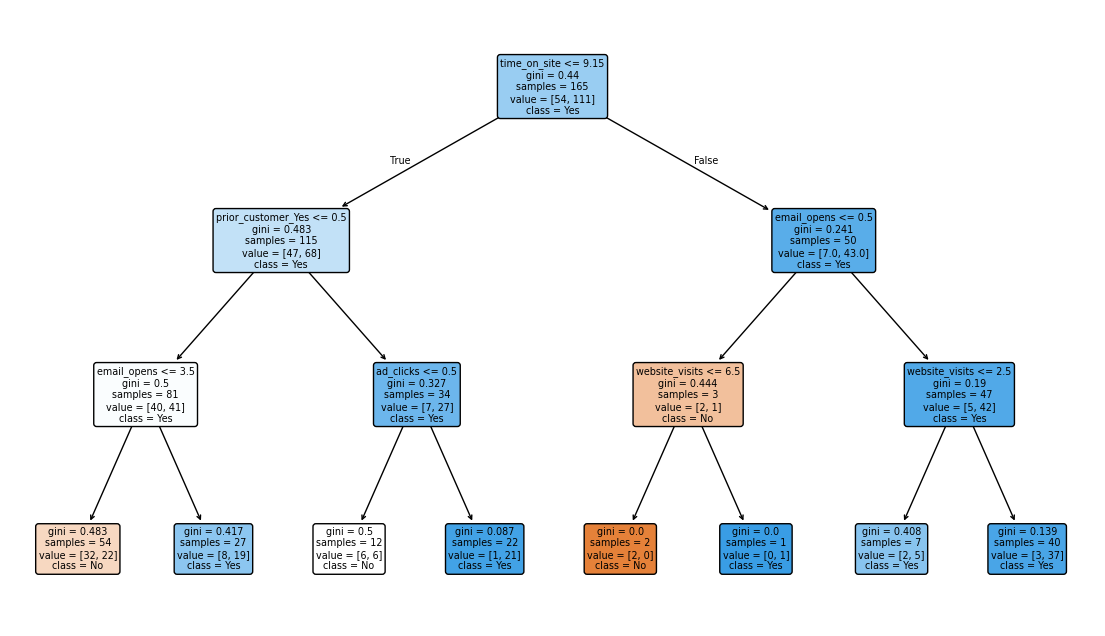

In [28]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Set the figure size so the tree is easy to read
plt.figure(figsize=(14, 8), dpi=100)

# Plot the decision tree
plot_tree(
    tree_clf,
    feature_names=X_train.columns,  # Assumes X_train is a pandas DataFrame; use a list of names if it's a numpy array
    class_names=["No", "Yes"],
    filled=True,
    rounded=True
)

# Display the plot
plt.show()


## Task 7. Compare with logistic regression
Fit a logistic regression model on the same training data.

Create a comparison table with metrics for:
- Logistic Regression
- Decision Tree


In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# 1. Initialize and fit the Logistic Regression model
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train, y_train)

# 2. Make predictions with Logistic Regression
log_reg_pred = log_reg.predict(X_test)

# 3. Calculate metrics for Logistic Regression
lr_acc = accuracy_score(y_test, log_reg_pred)
lr_prec = precision_score(y_test, log_reg_pred)
lr_rec = recall_score(y_test, log_reg_pred)
lr_f1 = f1_score(y_test, log_reg_pred)

# 4. Calculate metrics for Decision Tree (using your existing tree_pred)
dt_acc = accuracy_score(y_test, tree_pred)
dt_prec = precision_score(y_test, tree_pred)
dt_rec = recall_score(y_test, tree_pred)
dt_f1 = f1_score(y_test, tree_pred)

# 5. Create the comparison dataframe
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Logistic Regression': [lr_acc, lr_prec, lr_rec, lr_f1],
    'Decision Tree': [dt_acc, dt_prec, dt_rec, dt_f1]
})

# Set the 'Metric' column as the index for a clean look
comparison_df.set_index('Metric', inplace=True)

# Display the comparison table
display(comparison_df)


,Logistic Regression,Decision Tree
Metric,,
Accuracy,0.745455,0.654545
Precision,0.755556,0.750000
Recall,0.918919,0.729730
F1 Score,0.829268,0.739726


## Task 8. Business recommendation
Write 5–7 sentences:
1. Which model would you recommend?
2. Which model is easier to explain to a manager?
3. Which metric matters most for this business case?
4. What is one benefit of a decision tree?
5. What is one risk of a decision tree?
6. What should the company do before using the model in practice?


**Your answer:**


The decision tree is recommended because its intuitive, rule-based logic is much easier to explain to a manager than logistic regression's mathematical coefficients. For a sports betting addiction mitigation context, recall is the most critical metric because failing to catch a high-risk user poses a far greater consequence than a false alarm. A core benefit of decision trees is their transparent, flowchart-like interpretability that highlights specific behavioral triggers. However, a primary risk of decision trees is their tendency to overfit to the training data and fail on new patterns. Before using the model in practice, the company should rigorously validate it on out-of-sample data. Finally, they must establish supportive, ethical intervention protocols to ensure that flagged users are handled responsibly.